# U.S. Housing Price Analysis
**Author:** Reinier Acosta Marrero

Two questions, answered with listing data from realtor.com research data:

1. **Can square footage predict a home's listing price?** Simple linear regression on a random national sample of 50 homes.
2. **How does the East North Central region (IL, IN, MI, OH, WI) compare with the national market?** One-sample t-tests and a confidence interval on a random regional sample of 500 homes.

This notebook recreates in Python an analysis I first did in Excel for MAT 240 (Applied Statistics) at Southern New Hampshire University.

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
IMG = "../images/"

national = pd.read_csv("../data/national_sample_50.csv")
enc = pd.read_csv("../data/east_north_central_sample_500.csv")
print(national.shape, enc.shape)
national.head()

(50, 6) (500, 6)


,region,state,county,listing_price,price_per_sqft,square_feet
0,Pacific,CA,Sacramento,291500,176.132931,1655
1,East South Central,TN,Putnam,169700,97.305046,1744
2,West South Central,AR,Benton,232900,137.810651,1690
3,West South Central,AR,Baxter,286900,131.847426,2176
4,Mid Atlantic,NJ,Cumberland,314800,260.380480,1209


## Part 1: Square footage as a predictor of listing price

**Sampling:** Each row of the full dataset got a random value from Excel's `RAND()`. I sorted by that value and kept the first 50 homes.

- Predictor (x): square footage
- Response (y): listing price

In [2]:
national[["listing_price", "square_feet"]].agg(["mean", "median", "std"]).round(2)

,listing_price,square_feet
mean,326704.00,2185.34
median,289000.00,1826.00
std,143960.47,1212.84


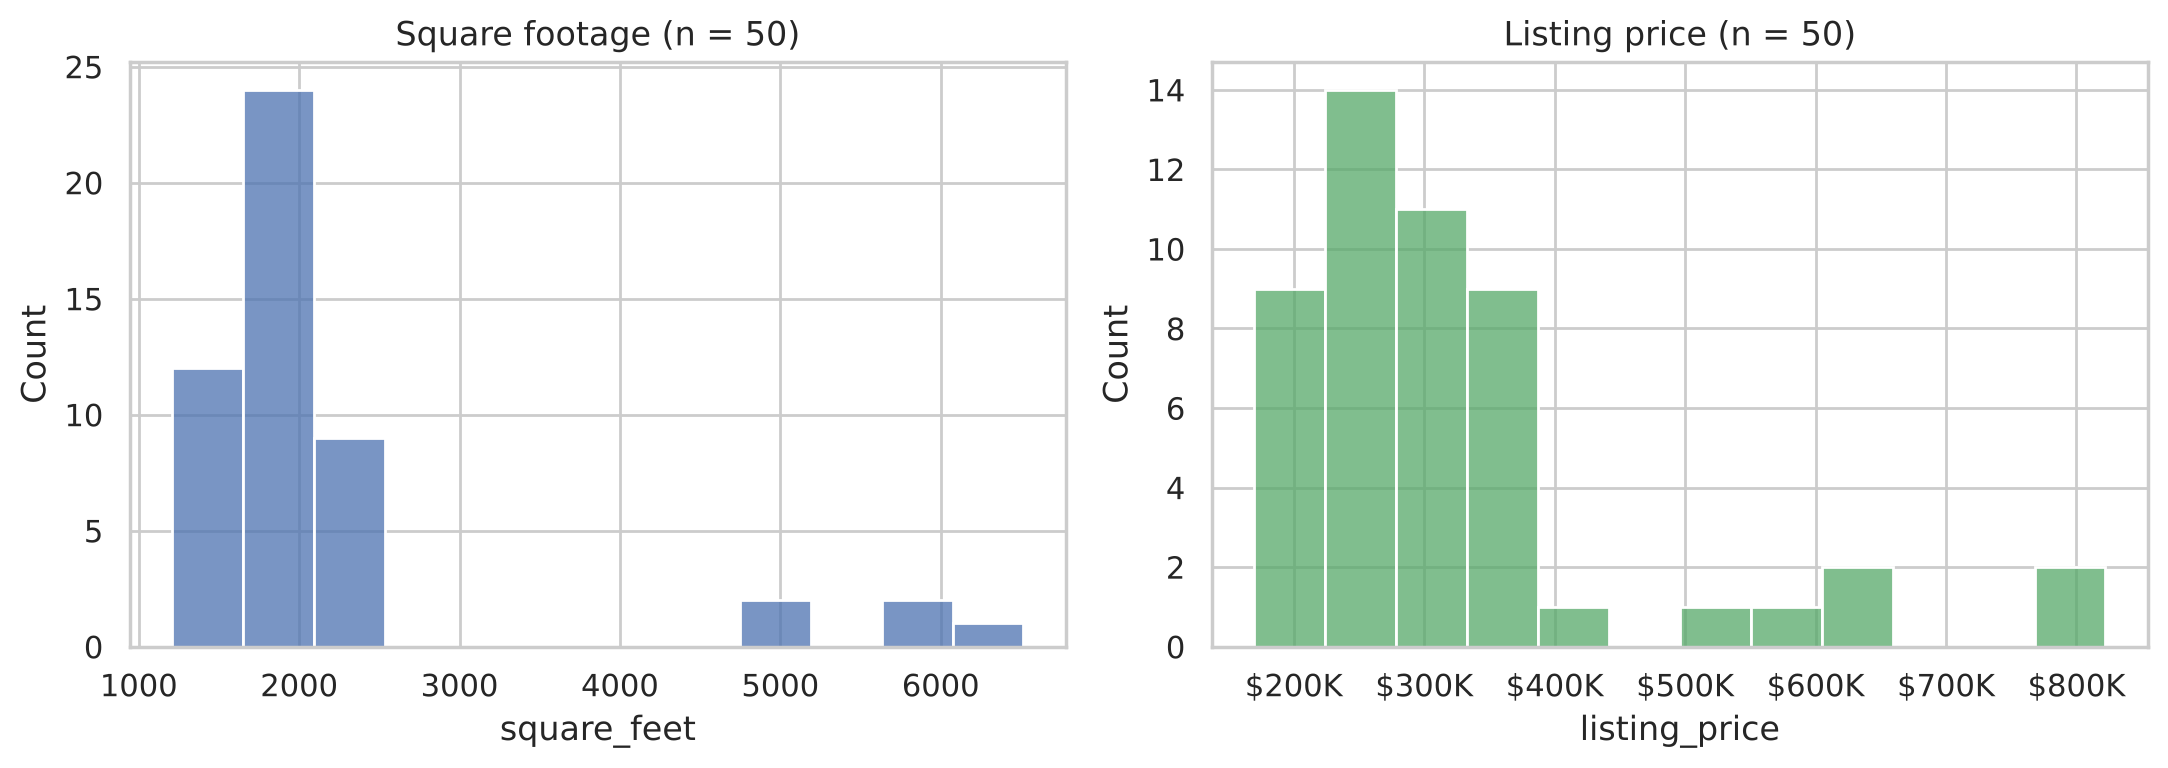

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(national["square_feet"], bins=12, ax=axes[0], color="#4C72B0")
axes[0].set_title("Square footage (n = 50)")
sns.histplot(national["listing_price"], bins=12, ax=axes[1], color="#55A868")
axes[1].set_title("Listing price (n = 50)")
axes[1].xaxis.set_major_formatter(lambda v, _: f"${v/1000:.0f}K")
plt.tight_layout(); plt.savefig(IMG + "distributions_national.png", dpi=150); plt.show()

Both variables are **right-skewed**. Most homes are around 1,800–2,000 sq ft and under $400K, and a few large, high-priced homes stretch the upper tail.

In [4]:
x, y = national["square_feet"], national["listing_price"]
model = stats.linregress(x, y)
print(f"Regression line: y_hat = {model.slope:,.2f}x + {model.intercept:,.2f}")
print(f"r   = {model.rvalue:.4f}")
print(f"R^2 = {model.rvalue**2:.4f}")
print(f"p-value (slope) = {model.pvalue:.2e}")

Regression line: y_hat = 100.99x + 106,007.02
r   = 0.8508
R^2 = 0.7239
p-value (slope) = 5.15e-15


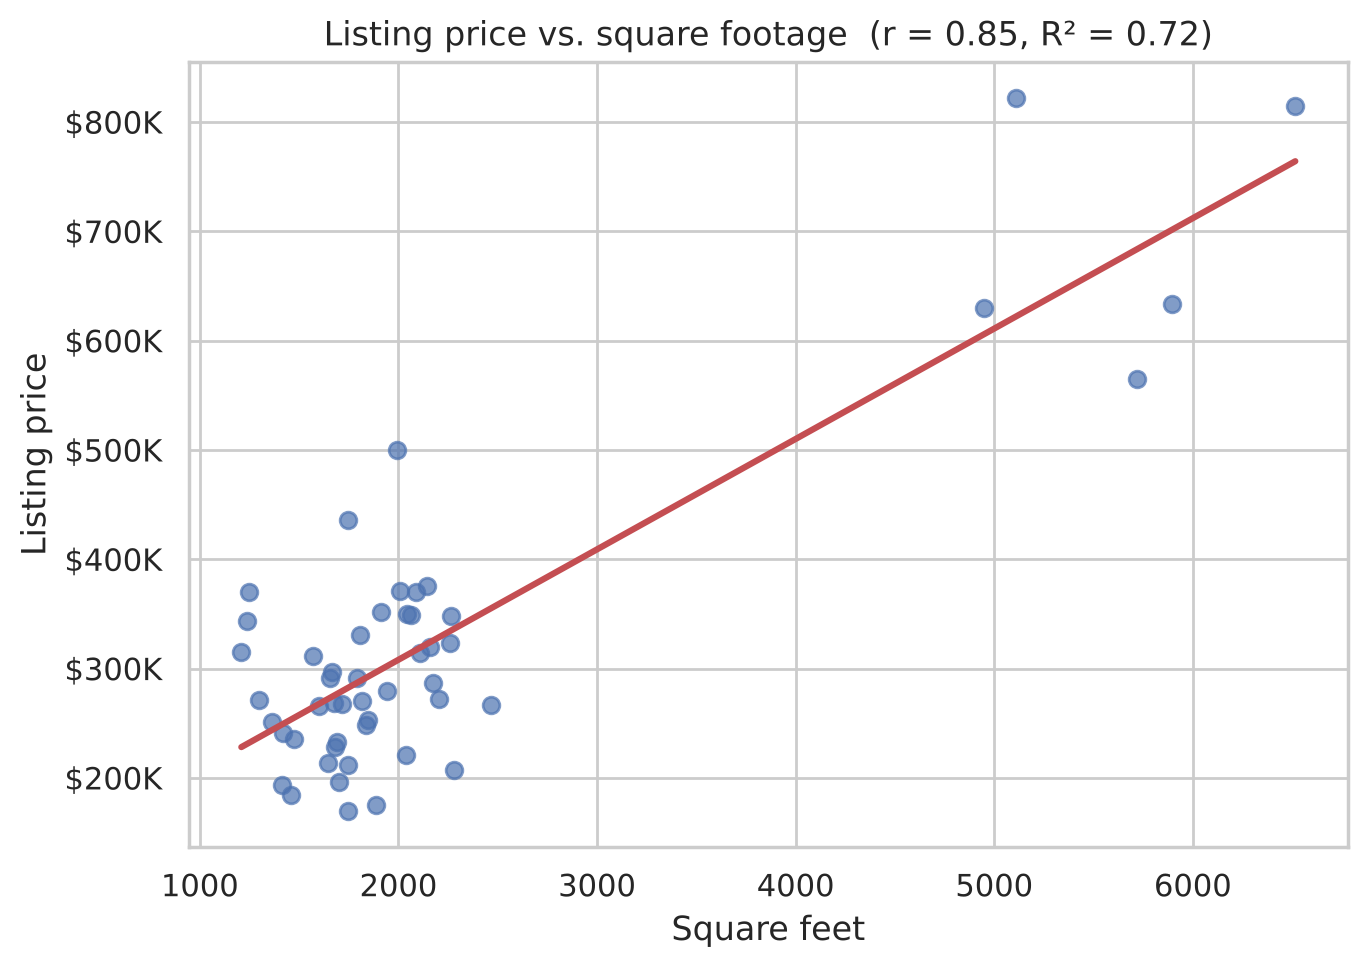

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.regplot(x=x, y=y, ci=None, ax=ax, scatter_kws={"alpha": 0.7}, line_kws={"color": "#C44E52"})
ax.set_xlabel("Square feet"); ax.set_ylabel("Listing price")
ax.yaxis.set_major_formatter(lambda v, _: f"${v/1000:.0f}K")
ax.set_title(f"Listing price vs. square footage  (r = {model.rvalue:.2f}, R² = {model.rvalue**2:.2f})")
plt.tight_layout(); plt.savefig(IMG + "regression_scatter.png", dpi=150); plt.show()

In [6]:
pred_1500 = model.slope * 1500 + model.intercept
print(f"Predicted listing price for a 1,500 sq ft home: ${pred_1500:,.0f}")

Predicted listing price for a 1,500 sq ft home: $257,492


**Interpretation**

- **Slope:** each additional square foot adds about **$101** to the expected listing price.
- **r = 0.85:** a strong, positive, linear relationship.
- **R² = 0.72:** square footage alone explains about 72% of the variation in listing price.
- **Prediction:** a 1,500 sq ft home is expected to list for about **$257,500**.
- **Outliers:** five homes are larger than 4,900 sq ft. They're real listings, so I tested how much the model depends on them (below).

### Sensitivity check: how much do the five large homes drive the model?

In [7]:
typical = national[national["square_feet"] < 4000]
m2 = stats.linregress(typical["square_feet"], typical["listing_price"])
pd.DataFrame({
    "Sample": ["All homes", "Homes < 4,000 sq ft"],
    "n": [len(national), len(typical)],
    "Slope ($/sq ft)": [model.slope, m2.slope],
    "r": [model.rvalue, m2.rvalue],
    "R²": [model.rvalue**2, m2.rvalue**2],
}).round(3)

,Sample,n,Slope ($/sq ft),r,R²
0,All homes,50,100.990,0.851,0.724
1,"Homes < 4,000 sq ft",45,46.849,0.209,0.044


**What this shows:** without the five large homes, R² falls from **0.72 to 0.04**. For typical homes (about 1,200–2,500 sq ft), square footage alone explains very little of the price differences. Location and other factors matter much more. The strong overall fit comes mostly from the size gap between the five luxury homes and everything else.

**Takeaway for a business user:** square footage is a reasonable first anchor for pricing, but it is not reliable on its own for mid-market homes. A better model would add location (region or county), bedrooms, and home age in a multiple regression, and would be fit on a larger sample than 50 homes.

## Part 2: East North Central vs. national market

**Sampling:** 500 homes from the East North Central region, picked at random with `RAND()`.

| Question | Test | Hypotheses |
|---|---|---|
| Are regional listing prices lower than the national mean ($288,407)? | One-sample t-test, left-tailed | H₀: μ = 288,407; H₁: μ < 288,407 |
| Is regional square footage different from the national mean (1,944 sq ft)? | One-sample t-test, two-tailed | H₀: μ = 1,944; H₁: μ ≠ 1,944 |

The significance level is α = 0.05 for both tests. The national means come from the national summary statistics provided with the course data.

In [8]:
NATIONAL_PRICE, NATIONAL_SQFT = 288_407, 1_944
summary = enc[["listing_price", "square_feet"]].describe().T[["count", "mean", "std", "25%", "50%", "75%"]]
summary["SE"] = summary["std"] / np.sqrt(summary["count"])
summary.round(2)

,count,mean,std,25%,50%,75%,SE
listing_price,500.0,200632.39,83819.64,135000.0,186725.00,250700.00,3748.53
square_feet,500.0,1837.00,399.48,1584.0,1749.43,1993.75,17.87


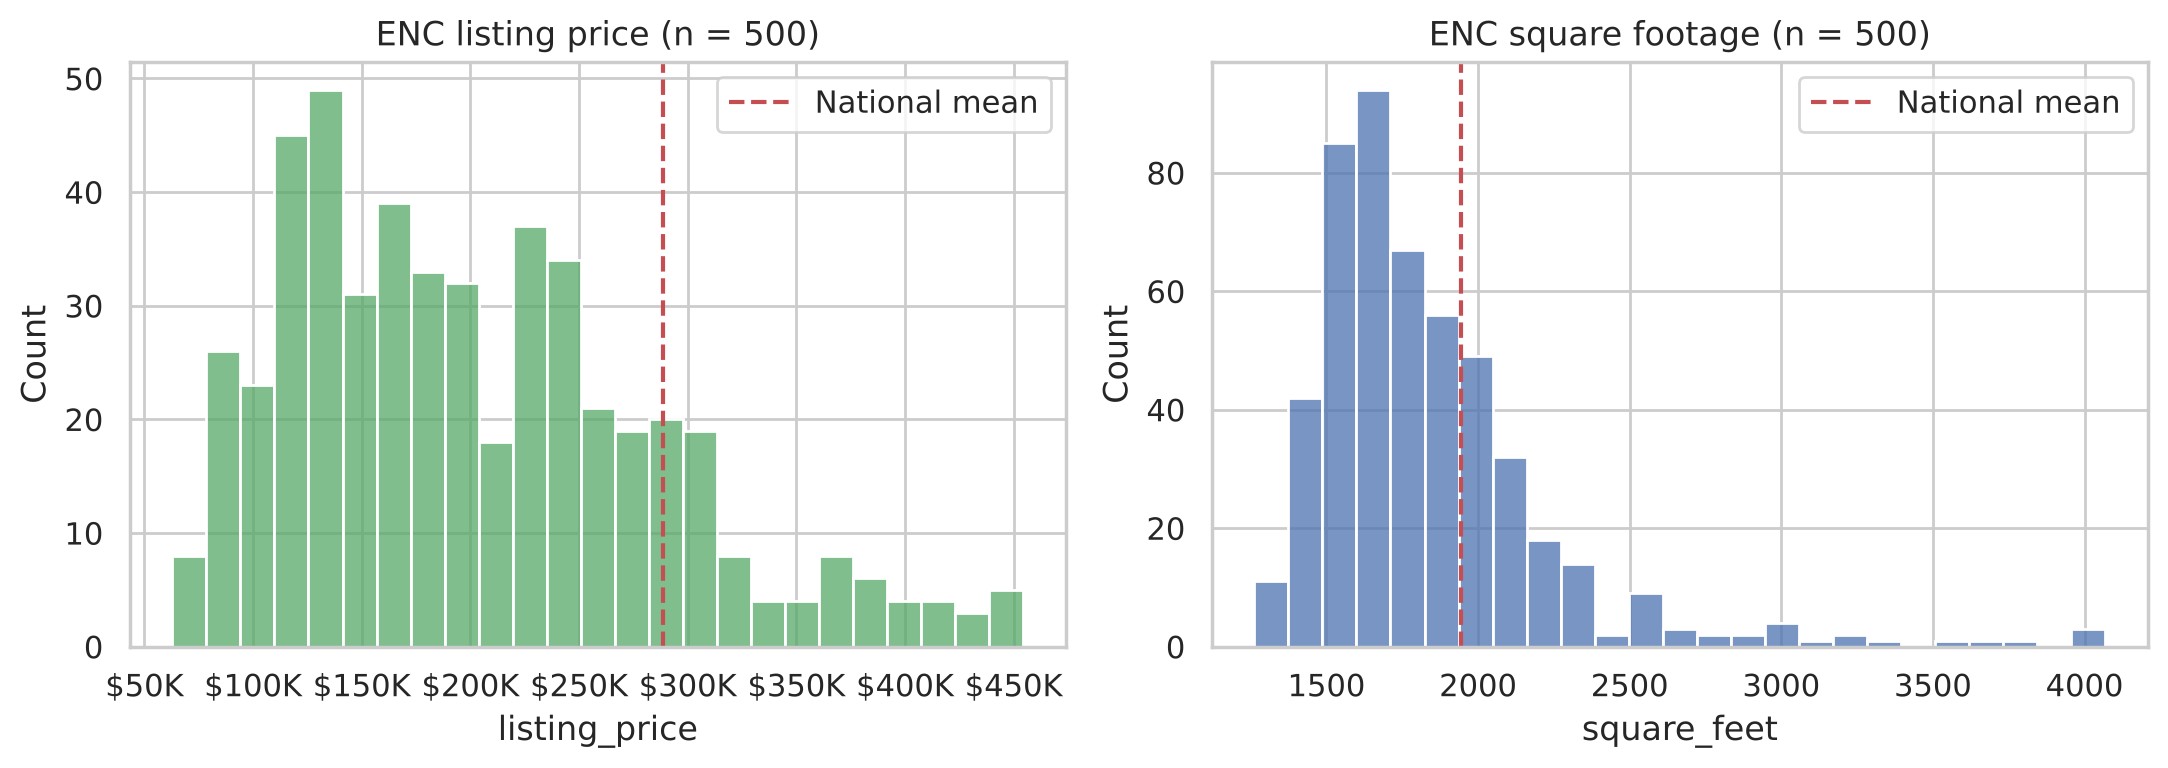

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(enc["listing_price"], bins=25, ax=axes[0], color="#55A868")
axes[0].axvline(NATIONAL_PRICE, color="#C44E52", ls="--", label="National mean")
axes[0].set_title("ENC listing price (n = 500)"); axes[0].legend()
axes[0].xaxis.set_major_formatter(lambda v, _: f"${v/1000:.0f}K")
sns.histplot(enc["square_feet"], bins=25, ax=axes[1], color="#4C72B0")
axes[1].axvline(NATIONAL_SQFT, color="#C44E52", ls="--", label="National mean")
axes[1].set_title("ENC square footage (n = 500)"); axes[1].legend()
plt.tight_layout(); plt.savefig(IMG + "distributions_enc.png", dpi=150); plt.show()

**Assumptions:** the samples were selected at random, and each listing is a separate property. With n = 500, the Central Limit Theorem means the sampling distribution of the mean is approximately normal even though the data are right-skewed.

In [10]:
t1, p1 = stats.ttest_1samp(enc["listing_price"], NATIONAL_PRICE, alternative="less")
print(f"Listing price  | mean = ${enc['listing_price'].mean():,.0f} | t = {t1:.2f} | p = {p1:.2e}")

t2, p2 = stats.ttest_1samp(enc["square_feet"], NATIONAL_SQFT)
print(f"Square footage | mean = {enc['square_feet'].mean():,.0f} sq ft | t = {t2:.2f} | p = {p2:.2e}")

ci = stats.t.interval(0.95, df=len(enc) - 1, loc=enc["square_feet"].mean(), scale=stats.sem(enc["square_feet"]))
print(f"95% CI for mean square footage: ({ci[0]:,.1f}, {ci[1]:,.1f})")

Listing price  | mean = $200,632 | t = -23.42 | p = 1.15e-82
Square footage | mean = 1,837 sq ft | t = -5.99 | p = 4.04e-09
95% CI for mean square footage: (1,801.9, 1,872.1)


**Results**

- **Price:** the regional mean of about **$200,600** is significantly lower than the national mean of $288,407 (t = −23.42, p < 0.001). Reject H₀.
- **Size:** the regional mean of about **1,837 sq ft** is significantly different from the national mean of 1,944 sq ft (t = −5.99, p < 0.001). Reject H₀.
- **95% CI:** the true regional mean is between **1,802 and 1,872 sq ft**. The interval doesn't include 1,944, which matches the two-tailed test.

**Conclusion:** homes in the East North Central region are cheaper and somewhat smaller than the national average. Price per square foot is also lower, so the lower prices are not explained by smaller homes alone.

In [11]:
ppsf = pd.DataFrame({
    "Sample": ["National (n=50)", "East North Central (n=500)"],
    "Median $/sq ft": [national["price_per_sqft"].median(), enc["price_per_sqft"].median()],
}).round(2)
ppsf

,Sample,Median $/sq ft
0,National (n=50),151.54
1,East North Central (n=500),98.91
